# PS3: RNN (SimpleRNN) for character-level text generation

## 1. Setup and GPU / VRAM check

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers

EPOCHS = 15
SEQ_LEN = 40

In [2]:
path = keras.utils.get_file(
    "shakespeare.txt",
    "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt")
text = open(path, encoding="utf-8").read().lower()[:200000]
chars = sorted(set(text))
char_to_id = {c: i for i, c in enumerate(chars)}
print("Characters:", len(text), "Vocabulary:", len(chars))
print(text[:300])

1115394/1115394 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Characters: 200000 Vocabulary: 37
first citizen:
before we proceed any further, hear me speak.

all:
speak, speak.

first citizen:
you are all resolved rather to die than to famish?

all:
resolved. resolved.

first citizen:
first, you know caius marcius is chief enemy to the people.

all:
we know't, we know't.

first citizen:
let us


In [3]:
encoded = np.array([char_to_id[c] for c in text])
starts = range(0, len(encoded) - SEQ_LEN, 3)
X = np.array([encoded[i:i + SEQ_LEN] for i in starts])
y = np.array([encoded[i + SEQ_LEN] for i in starts])
print("X:", X.shape, "y:", y.shape)

X: (66654, 40) y: (66654,)


In [4]:
model = keras.Sequential([
    layers.Input((None,)),
    layers.Embedding(len(chars), 64),
    layers.SimpleRNN(256),
    layers.Dense(len(chars), activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, None, 64)       │         2,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 256)            │        82,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 37)             │         9,509 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,053 (367.39 KB)

 Trainable params: 94,053 (367.39 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(X, y, batch_size=128, epochs=EPOCHS, validation_split=0.1, verbose=2)

Epoch 1/15
469/469 - 11s - 23ms/step - accuracy: 0.2798 - loss: 2.5441 - val_accuracy: 0.3248 - val_loss: 2.3204
Epoch 2/15
469/469 - 3s - 7ms/step - accuracy: 0.3667 - loss: 2.1703 - val_accuracy: 0.3741 - val_loss: 2.1616
Epoch 3/15
469/469 - 3s - 7ms/step - accuracy: 0.4082 - loss: 2.0127 - val_accuracy: 0.3900 - val_loss: 2.0796
Epoch 4/15
469/469 - 3s - 6ms/step - accuracy: 0.4368 - loss: 1.9000 - val_accuracy: 0.4038 - val_loss: 2.0309
Epoch 5/15
469/469 - 3s - 6ms/step - accuracy: 0.4614 - loss: 1.8073 - val_accuracy: 0.4236 - val_loss: 1.9670
Epoch 6/15
469/469 - 3s - 7ms/step - accuracy: 0.4807 - loss: 1.7322 - val_accuracy: 0.4241 - val_loss: 1.9531
Epoch 7/15
469/469 - 3s - 7ms/step - accuracy: 0.4967 - loss: 1.6700 - val_accuracy: 0.4395 - val_loss: 1.9129
Epoch 8/15
469/469 - 3s - 7ms/step - accuracy: 0.5114 - loss: 1.6159 - val_accuracy: 0.4428 - val_loss: 1.9054
Epoch 9/15
469/469 - 3s - 7ms/step - accuracy: 0.5235 - loss: 1.5703 - val_accuracy: 0.4550 - val_loss: 1.8859

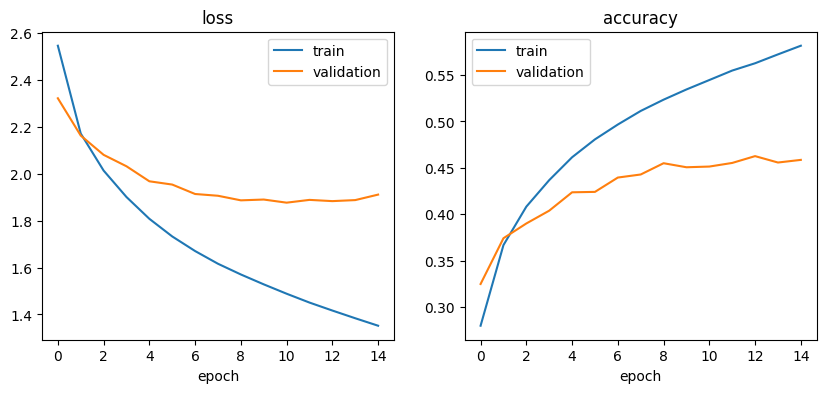

Final validation accuracy: 0.4586
Validation perplexity: 6.76


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(["loss", "accuracy"]):
    ax[i].plot(history.history[metric], label="train")
    ax[i].plot(history.history["val_" + metric], label="validation")
    ax[i].set_title(metric)
    ax[i].set_xlabel("epoch")
    ax[i].legend()
plt.show()
print(f"Final validation accuracy: {history.history['val_accuracy'][-1]:.4f}")
print(f"Validation perplexity: {np.exp(history.history['val_loss'][-1]):.2f}")

In [7]:
def generate(seed, length=300, temperature=0.5):
    out = seed.lower()
    for _ in range(length):
        x = np.array([[char_to_id[c] for c in out[-SEQ_LEN:]]])
        probs = model(x, training=False).numpy()[0].astype("float64")
        probs = np.exp(np.log(probs + 1e-9) / temperature)
        probs /= probs.sum()
        out += chars[np.random.choice(len(chars), p=probs)]
    return out


seed = text[1000:1000 + SEQ_LEN]
for t in [0.2, 0.5, 1.0]:
    print(f"--- temperature {t} ---")
    print(generate(seed, temperature=t))
    print()

--- temperature 0.2 ---
second citizen:
would you proceed especitions than their some to the sunery.

brutus:
gring the people their loves, and the people to his counter and to make the people, and the deather, and to make the people, and the some to the compon the such a man be and the death of the people, and to make the people, and the death, not the deed to 

--- temperature 0.5 ---
second citizen:
would you proceed especites their leave be was my some senatore, letver hold to the genter to his coriolanuseds of remeine
so like and trum his probed
the good to have have of our state,
and the marks death your swords.

second citizen:
your net the people's peronce; and you,
when more hers of sto him not in the some to di

--- temperature 1.0 ---
second citizen:
would you proceed especion,
thing them, i natter reed him.

menenius:
we wis hews behory deort; but me nabunin?

cominius:
his turt tresws,
ir wo maget as 'pounded.

coriolanus:
grow'gl her pusine; and for too.

lartius:
he pers